In [3]:
import numpy as np 

In [4]:
PD = np.array([0.012,0.035,0.04,0.015,0.045])
LGD = np.array([0.4,0.45,0.4,0.2,0.65])
EAD = np.array([42,28,9,31,14])
El =PD*LGD*EAD
print(El)
print (El.sum())
print(EAD[PD>0.03])

[0.2016 0.441  0.144  0.093  0.4095]
1.2891000000000001
[28  9 14]


In [5]:
#liste : *2 lal liste est répétée 2 fois 
[0.012,0.035]*2

[0.012, 0.035, 0.012, 0.035]

In [6]:
#Tableau Numpy 
np.array([0.012,0.035])*2

array([0.024, 0.07 ])

In [7]:
#nbre de valeur 
len(PD)
len(El)

5

In [8]:
#La valeur maximale
El.max()

0.4410000000000001

In [9]:
#Position de la plus valeur maxiname
El.argmax()

1

In [10]:
#42 est la seed 
rng=np.random.default_rng(42) 
#tirer selon la loi normal :random number generator suivant une loi normale :rng (Moy, Ecrartype,nbre tirage)
rendement =rng.normal(0,0.02,10000)
#Les  premiers 3  jours 
print(rendement[0:3])
print(len(rendement))

[ 0.00609434 -0.02079968  0.01500902]
10000


In [11]:
#tirer selon la la loi de student avec degré de liberté de 4 
t=rng.standard_t(4,10000)*0.02/np.sqrt(2)
print(t[0:3])

[ 0.00199666 -0.00330392  0.04976735]


In [12]:
#Vérifier que la moyenne et l'écart-type std simulés retombent sur les paramètres choisis
print(rendement.mean())
print(rendement.std ())

-0.00020499750828023306
0.02012571537074082


In [13]:
#la pire journée simulée 
perte =-rendement 
print (perte.max())
#posant une valeur de 100 
valeur=100
perte=-rendement *valeur 
print (perte.max())

0.08778229169729673
8.778229169729673


In [14]:
#situer quantile : Le quantile à 99 % est la valeur sous laquelle se trouvent 99 % des pertes
np.quantile(perte,0.99)

4.747622395834744

In [15]:
#filtrer : filtre booléen
masque =perte > 4.74   # pertes[pertes > var99].mean()
print(masque[0:5]) # est cque les perte > 4;74 sont dans les premiers jours ?  
print(masque.sum()) #nombre de true ou perte >4;74 , cad somme de jours

[False False False False False]
102


In [16]:
#Mettre le masque entre crochets garde uniquement les valeurs là où il vaut True
pire_jours=perte[masque]   #pertes[pertes > var99]
print(len(pire_jours))
print(pire_jours.mean())    #pertes[pertes > var99].mean()

102
5.436114751220098


In [17]:
#La VaR dit où commence une très mauvaise journée ; l'ES dit combien elle coûte en moyenne quand elle arrive.
VaR99=np.quantile(perte ,0.99)
print(VaR99) # 99 jours sur 100, la banque perd moins de 4,75 M MAD. » C'est un seuil, pas un maximum : 1 jour sur 100, on fait pire.

4.747622395834744


In [18]:
ES99=perte[perte>VaR99].mean()
print(ES99)

5.44991761461252


In [19]:
#Normale ou Student ? La loi normale suppose que les krachs sont extrêmement rares , La loi de Student reproduit ces queues épaisses.Utiliser la loi normale, c'est donc sous-estimer le risque de queue
#stress test : doubler PD
PD = np.array([0.012,0.035,0.04,0.015,0.045])*2
LGD = np.array([0.4,0.45,0.4,0.2,0.65])
EAD = np.array([42,28,9,31,14])
print (PD)
EL=PD*LGD*EAD
print(EL.sum())

[0.024 0.07  0.08  0.03  0.09 ]
2.5782000000000003


In [20]:
#filtre
masque = PD>0.03
print (EAD[masque])
print (masque.sum())

[28  9 14]
3


In [21]:
#simuler et controle de cohérence
rng=np.random.default_rng(42)
rendement =rng.normal(0,0.02,10000)
print(rendement.mean())
print(rendement.std())

-0.00020499750828023306
0.02012571537074082


In [22]:
Valeur =100
pertes=-rendement*Valeur
VaR99=np.quantile(pertes,0.99)
print(VaR99)
ES99=pertes[pertes>4.74].mean()
print(ES99)

4.747622395834744
5.436114751220098


In [23]:
VaR95=np.quantile(pertes,0.95)
print(VaR95)
ES95=pertes[pertes>VaR95].mean()
print(ES95)

3.3481869746674118
4.184624099392337


la VaR 95% est plus basse car on se déplace vers les pertes les plus basses , la droite de la VaR se déplace à gauche . la ligne de la VaR se déplace vers la gauche, vers des pertes plus petites.
Avec la VaR 95 %, on laisse 5 % des jours dans la queue, contre 1 % pour la VaR 99 %. La queue est donc plus large : elle contient 500 jours au lieu de 100. Pour en faire entrer 400 de plus, la frontière doit reculer vers des pertes moins extrêmes : 3,35 au lieu de 4,75.

In [24]:
rendement_t =rng.standard_t(4,10000)*0.02/np.sqrt(2)
print (rendement_t)
Valeur =100
Pertes_t=-rendement_t *Valeur  
VaR_t99=np.quantile(Pertes_t,0.99)
ES_t99=Pertes_t[Pertes_t>VaR_t99].mean()
print (VaR_t99)
print(ES_t99)

[ 0.00199666 -0.00330392  0.04976735 ...  0.08293557 -0.02496627
 -0.01696985]
5.090350655138609
6.7696271139620965


In [31]:
print(f"{"loi":<12},{"VaR 99%":>10},{"ES 99%":>10}")
print(f"{"Normale":<12},{VaR99:>10.2f},{ES99:>10.2f}")
print(f"{"t-student":<12},{VaR_t99:>10.2f},{ES_t99:>10.2f}")

loi         ,   VaR 99%,    ES 99%
Normale     ,      4.75,      5.44
t-student   ,      5.09,      6.77


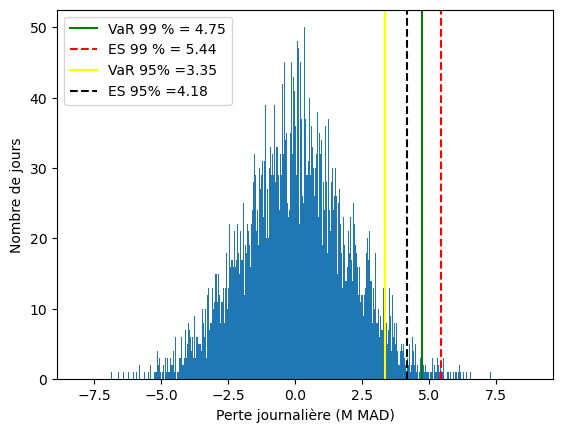

In [57]:
import matplotlib.pyplot as plt

plt.hist(pertes, bins=1000)
plt.axvline(VaR99, color="green" ,  label=f"VaR 99 % = {VaR99:.2f}")
plt.axvline(ES99, color="red",linestyle="--" ,  label=f"ES 99 % = {ES99:.2f}")
plt.axvline(VaR95 ,color="yellow" , label=f"VaR 95% ={VaR95:.2f}")
plt.axvline(ES95 , color="black", linestyle="--" , label=f"ES 95% ={ES95:.2f}")
plt.xlabel("Perte journalière (M MAD)")
plt.ylabel("Nombre de jours")
plt.legend()
plt.show()